# When Correcting Maximization Bias Hurts Q-Learning

In Q-learning, we estimate the value of the next state by taking the maximum of its estimated action values. This operation introduces a positive bias. Double Q-learning was designed to address this problem. But how does reducing the bias of the estimator affect the policy learnt by the agent?

While experimenting with a few variants of Q-learning, I found that the answer depends quite strongly on the exploration strategy. In some cases, Double Q-learning learnt the wrong policy despite thousands of episodes of training. We will use a simple environment from Sutton and Barto to understand why this happens and then use the Uncertainty Bellman Equation to investigate a possible solution.

## The Maximization Bias Problem

Consider the environment in Example 6.7 of [Reinforcement Learning: An Introduction](http://incompleteideas.net/book/the-book-2nd.html). The agent starts at state $A$ and has two actions. Going right terminates the episode with a reward of 0. Going left takes the agent to state $B$, also with a reward of 0. At $B$, there are ten actions, each of which terminates the episode with a reward drawn from $\mathcal N(\mu,\sigma^2)$.

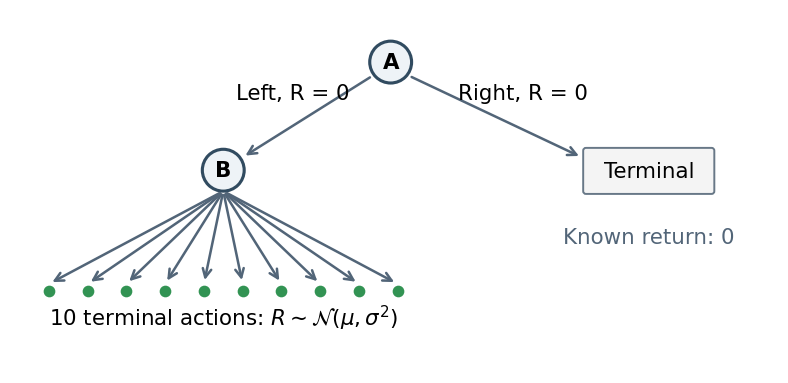

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch
from IPython.display import display

plt.rcParams.update({'figure.dpi': 140, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .23})
colors = {'Maximum': '#2475ad', 'Double Q': '#e3812b', 'Gaussian': '#329353'}
labels = {'Maximum': 'Q-learning', 'Double Q': 'Double Q-learning', 'Gaussian': 'Gaussian-weighted'}
methods = list(colors)
fig, ax = plt.subplots(figsize=(8.5, 3.3))
ax.set(xlim=(-.4, 10.5), ylim=(-.5, 4.6), aspect='equal')
ax.axis('off')
for x,y,s in [(5,3.9,'A'),(2.6,2.35,'B')]:
    ax.add_patch(Circle((x,y),.30,fc='#eef3f7',ec='#314b60',lw=1.6))
    ax.text(x,y,s,ha='center',va='center',weight='bold')
def arrow(start,end):
    ax.annotate('',end,start,arrowprops=dict(arrowstyle='->',color='#526578',lw=1.3))
arrow((4.75,3.71),(2.87,2.53)); arrow((5.25,3.71),(7.75,2.53))
ax.text(3.6,3.37,'Left, R = 0',ha='center');ax.text(6.9,3.37,'Right, R = 0',ha='center')
ax.add_patch(FancyBboxPatch((7.8,2.05),1.8,.58,boxstyle='round,pad=.04',fc='#f4f4f4',ec='#687887'))
ax.text(8.7,2.34,'Terminal',ha='center',va='center')
for x in np.linspace(.1,5.1,10):
    arrow((2.6,2.05),(x,.72)); ax.plot(x,.62,'o',color='#329353',ms=5)
ax.text(2.6,.13,r'10 terminal actions: $R\sim\mathcal{N}(\mu,\sigma^2)$',ha='center')
ax.text(8.7,1.3,'Known return: 0',ha='center',color='#526578')
plt.show()

With $\gamma=1$, the optimal action values are particularly easy to calculate:

$$Q^*(A,L)=\mu,\qquad Q^*(A,R)=0,\qquad Q^*(B,a)=\mu.$$

In the original environment, $\mu=-0.1$ and $\sigma=1$. The optimal policy is to go right at $A$. The TD update for the left action is

$$Q(A,L)\leftarrow Q(A,L)+\alpha\left[\max_a Q(B,a)-Q(A,L)\right].$$

Suppose that the estimates of the individual action values are unbiased. The maximum, however, is a convex function. By Jensen's inequality,

$$\mathbb E[\max_a\widehat Q(B,a)]\geq\max_a\mathbb E[\widehat Q(B,a)]=\mu.$$

As the number of actions or the uncertainty of their estimates increases, this effect can become quite large. The inequality assumes unbiased individual estimates; it does not imply that the maximum has positive bias under every adaptive sampling scheme.

### Double Q-Learning

[Double Q-learning](https://proceedings.neurips.cc/paper_files/paper/2010/hash/091d584fced301b442654dd8c23b3fc9-Abstract.html) (van Hasselt, 2010) maintains two Q-tables. One table selects the action and the other evaluates it. When updating $Q_1$,

$$i=\arg\max_a Q_1(B,a),\qquad Y=Q_2(B,i).$$

When updating $Q_2$, the roles are reversed. The behavior policy uses $Q_1+Q_2$ (or their average, with the same greedy ranking). If the two tables are independent and the individual estimates are unbiased, the positive error responsible for selecting an action does not also inflate its evaluation. For equal true action values, this cross-estimate is unbiased under those assumptions. With unequal values it can underestimate the maximum by selecting the wrong action.

### Gaussian-Weighted Q-Learning

Double Q-learning splits the available experience between two tables. Can we reduce maximization bias while using every observation to estimate an action value?

A weighted estimator was proposed by D'Eramo et al. in [Estimating Maximum Expected Value through Gaussian Approximation](https://proceedings.mlr.press/v48/deramo16.html) (2016). We approximate the uncertainty about each action value using a Gaussian:

$$X_a\sim\mathcal N(\widehat Q_a,\widehat{\mathrm{SE}}_a^2),\qquad w_a=P(X_a=\max_b X_b).$$

We then calculate $\widehat V(B)=\sum_a w_a\widehat Q_a$. Note that we weight the original Q-values rather than the sampled Gaussian values. We can approximate the weights by drawing samples from these distributions and counting how often each action has the largest value. Here's the corresponding JAX implementation, assuming the standard errors have already been estimated.

In [2]:
import jax
import jax.numpy as jnp

@jax.jit
def gaussian_backup(key, q, se):
    samples = q + se * jax.random.normal(key, (100, q.size))
    winners = jnp.argmax(samples, axis=1)
    return q[winners].mean()

q = jnp.array([-.2, .1, .2])
se = jnp.full_like(q, .2)
print(f'Maximum: {q.max():.3f}')
print(f'Gaussian-weighted: {gaussian_backup(jax.random.key(0), q, se):.3f}')

Maximum: 0.200


Gaussian-weighted: 0.158


This is a small illustrative calculation, not one of the recorded runs. The experiments use running means and variances of the samples, with a fallback standard error for actions without enough observations. The Gaussian approximation ignores possible correlations between action estimates.

## Comparing the Three Estimators

In the first experiments, we reproduced the maximization-bias example and compared the three estimators using $\epsilon=0.1$. Below is the original plot from the constant-learning-rate comparison ($\alpha=0.1$, 300 episodes). An optimal $\epsilon$-greedy behavior policy goes left in $\epsilon/2=5\%$ of episodes.

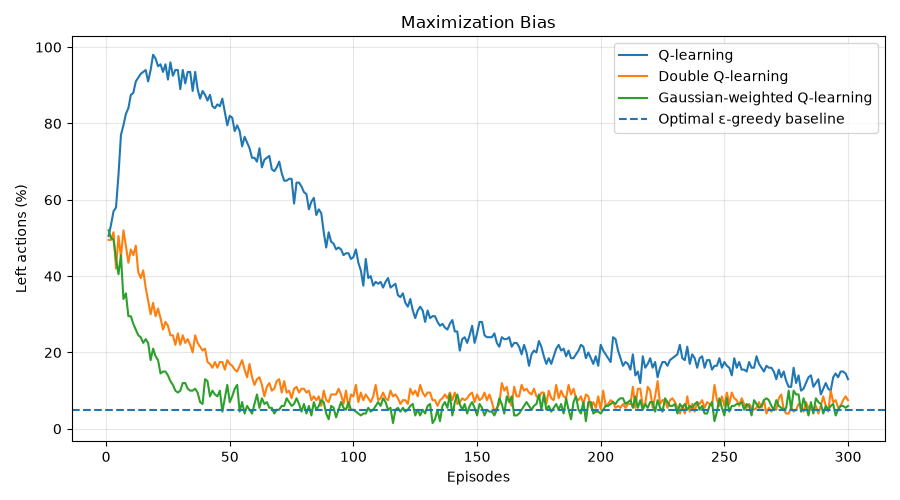

*Original constant-step-size learning curves (experiments 1–2).*

Both Double Q-learning and Gaussian weighting substantially reduce the number of suboptimal left actions. Gaussian weighting initially looked particularly promising. But the relative performance changed when we replaced the constant learning rate with $\alpha_n=n^{-0.8}$, where $n$ is the number of updates to that entry.

![Left-action rate with decaying alpha](attachment:Figure_1(6).png)

*Original uncapped-decay comparison (experiment 3; 300-episode figure).*
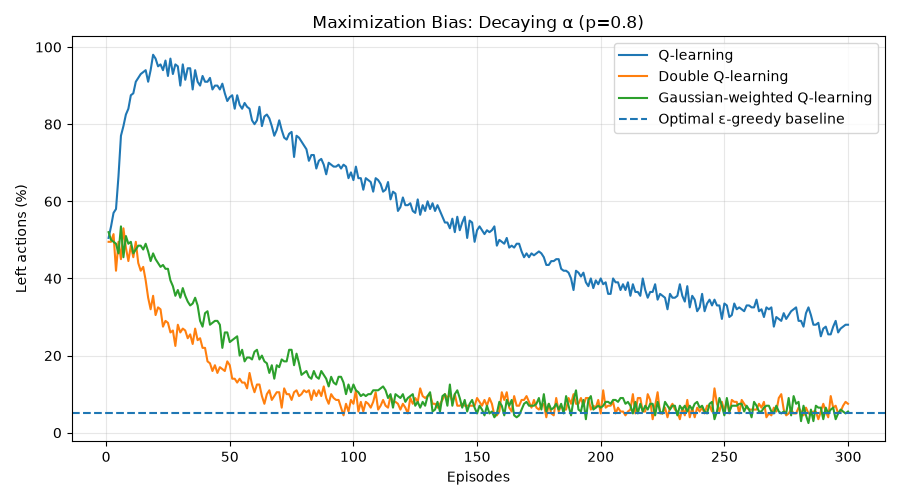

### Sensitivity to the Learning Rate

The decaying schedule starts with a learning rate of 1. This means the first observation completely determines the initial Q-value estimate. We therefore tried a capped schedule (experiment 4):

$$\alpha_n=\min(c,n^{-0.8}).$$

Unlike a constant learning rate, this schedule satisfies both Robbins–Monro step-size conditions, while the cap limits the influence of early observations. Gaussian weighting regained its advantage with a cap of 0.1. However, it did not seem reasonable to assume that the same cap was optimal for all three algorithms.

We ran a sweep over $c\in\{0.05,0.1,0.2,0.5,1\}$ for 5,000 episodes (experiment 5). The quantity plotted below is Double Q-learning's regret minus Gaussian weighting's regret, so positive values favor Gaussian weighting. The original comparison used independent algorithm streams; the intervals are pointwise.

![Learning rate sensitivity: difference in regret](attachment:Figure_3(2).png)

*Original learning-rate sweep. A change to the cap can reverse the ranking.*
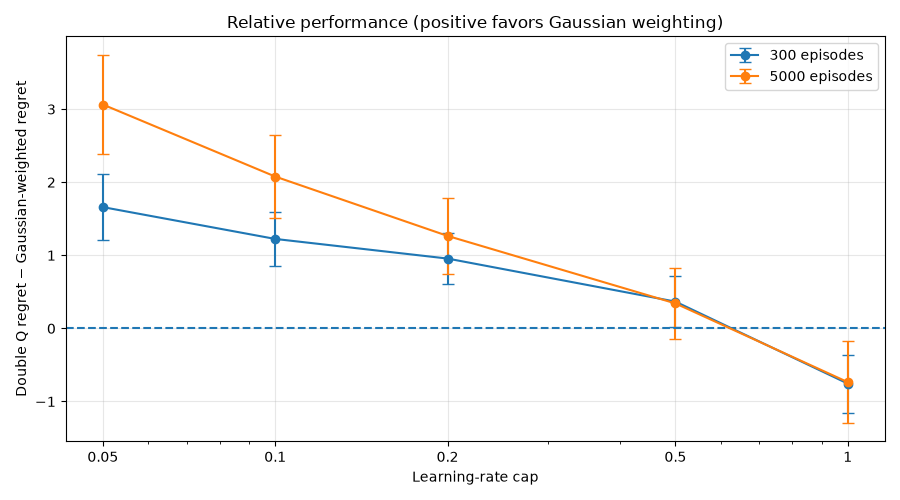

For the earlier runs we have the original figures and the learning-rate scripts, but not all of the numerical console logs. I will use those figures rather than quote unverified exact early-run metrics.

### Sensitivity to Reward Variance

We initially chose caps $(1,0.5,0.1)$ for Maximum, Double and Gaussian estimation, respectively. We then varied the reward standard deviation (experiment 6). Gaussian weighting did well at low noise but Double Q-learning did better at high noise. Since the learning rates had been tuned at $\sigma=1$, we repeated the sweep jointly over reward noise and the learning-rate cap (experiment 6b).

We used 200 runs for tuning (seed 43), then evaluated the selected caps on 400 independent runs (seeds 53 and 54). The objective was cumulative excess regret after 5,000 episodes. In this MDP, regret per episode is $0.1$ if the agent goes left, and zero otherwise. Subtracting the expected exploration cost of an optimal $\epsilon$-greedy policy gives

$$R_{\mathrm{excess}}=0.1\sum_{t=1}^{T}\mathbf 1[A_t=L]-0.1T\epsilon/2.$$

The baseline subtraction does not change the ranking of algorithms trained with the same constant $\epsilon$.

In [3]:
import base64
import gzip
import io

noise = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode('H4sIAAAAAAAC/02QTU7DMBCF9zkFB5iOPH92vK/EigUnQKFNq0hNGxpFcHxmXEAsMs9jz/eenXU6zwO8DF/TvM2wv23vl/HpFZ6HbV2n4QrH6XQa7+P1MMLl9jneYVsWrx9vh2GBY6vnqF1CAkLr1SBhrlHZJESVWsdV48gkR+df7FoXc6BItTG1JAmGuZ1qKS7CmVxKdgfC9INSF0qEWqz3fc2PbGtoTy3CegkkW/kNbGS4iC8SAWNicx/kGjOF+3Zpopallv9FcufTkAWrKDtpIgKCpCqw82gi2BESJ4vW3R+JDwPq1JWIMSjGyv5Uxb5KQLVwgZ1b1txMRNvv4j/4G59qapaqAQAA'))))
bandit = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode('H4sIAAAAAAAC/2VWy44cNwy871fkAzoNvindDfiUQz5hHCzsAXbiwOMN8vmhRHW3tD4RO1PL4qOKmuf96+O2PW+Pf95en9vt7ev3H/ef3x7bl/vtuf17+3G//f3X6/Z4vr7Arhtuf9z+uz/eHxvspK4YEaxiiYisUgfq0/f3L2+vv/3Zvq7xeYuIUlskIBmwz7f35zMY2n+To7WvwbnDiRUTBhOpFq+NDIpDyyZMhQ7YzKqm3Nm9s2PLe+AmWmKAno/FRl7LfDrTcjG1hFFLi4XNDthJ+3vrErh2vlrbcDCIz3wzr3qfHXNvo6HH7ADWGVfN4VnHe0E9cXO/wAkwLj5iOYHznAuAZUbvUQQTyAszinLug5H6PoT0xC3MUVJPWDz3XAqewJk5SuSRsZeKXM5eZmpwsz6USN0zgjldwGXckKlA4YgTciIH5SojJ2URQw/6gZwlNx2p+yCjTLuAKznIqLPSES/ozE4iuiQF9xfcYTGUaGkS5Db6JnVS4AFa/ERUcnG9L1IaoFlebatdftqXgh7bTNjVLMbH3MpiZcH40xnCcwM1U0ougrUvkEOUfsAmUgesrTsOE7QReuWStS1eck9FxVxrSxd+Nzlgy3ypaOkeV6MeTfgATrwavXbPhZ4kb0JIOutbbgdq9yQEX28HyU7Yomgr1s2nWjOOAj94iS2knAlrL8Ct5PxWL1GFdDtSCmaM76OT0Kh/7ZI3zpXkBM7bBScb+bqjVPlseDGxMqfeuC8ayIpfwFXMlDYf56HFC7nY2EuqnqnnjrOOYyurk+JdSFNCnlZQsQv4wUl15BzQiBd0dpIM8rgJCYwyZTES7uYei9Ndgxi3socekAdqnncRbz1bTf9aje3JaiXcY4Qh/khm7db4XuOlGpRXt7JbXD0OmIOFaMnjA0U/cOsT4UAtIRUpGf0EnsQSF9jiVFnIm8LDxGGUMgqc/MTtIIhvtGONS7xh2DgM4QduZkYhlMhYFUPgET2UdABPZgrBU+iawkhNiB5zjJWPCi9mao+MNSO5MLRO4rqZn7h50qRM0RKU1nKLMcUTOA07zlbTafyw8FZAoWq5uNlQcbeMukOxVi9tRxo/Kk7cTGzRavuHWkMvGM7hiidw0lUwQT9KtfT3sxSLh1Z+tZRhOknzV41QrXThVlGX/tQwQX96QoUwQSdyYdRxzPubS3HIytjLekjc8h1ByFe+ONULuLJz/nLQko9TRLmgs6FrnrlI6j2pxChe/gf3DhW/GAoAAA=='))))
controlled = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode('...'))))
ube = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode('...'))))
comparisons = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode('H4sIAAAAAAAC/7192ZJlt7Hdu7/CH1BUAInE9O4IP/nBX6CgaFpiBCXeEMWw/fdeC4nTXd11ztmZ0KnbHLp718a0kVg5IIe///H2+y9//fuPbz/++tff/vnLv/7297f/+O3XX376f29/+flfP7798+f//fM/f/7HTz+//fwfv/z+2//6GU/+9cc///Hnv/74yz/efvrlz7/+9n/4299++evf/ssP+U/pLf2pvv2PH//vL3//4+9vf/z0F/w9oe3vv/z62z/e0vrb/u/69Rx8Pb39gL+nVNP6JaXr6PasSpI858T/e5tsltQejaqtT73uvq5ppGydJ+06u+4RZ1v/4whZ1mtij3rWOVr2TD74cUq0ASceayHhFvWyxa+//fTjr3/+1+9v2U8Xd9vkkzZ7CzeB5JLKqLaFpfdZ1o7Vlut6rdmjLKXhNecQr6WSB6s4+V7lqFU+21A5a3ZNPn/85ecI5Xz/eg6+/lJ6+b73FwPKh7kHv02JNsjh3ZJwCz9FfCGo6Ps5+n50gBqeUXjNJR2MEW0i8SYBfiAH/EAO+IF8Pj+QD4fc+hRNuaO9ljqrCSHfPnJP++QDlaNW+WwH5ayZ77hLjAFIjAHIpzKAF9LGx8kGP0aJNsjh7ZFwCz8JRBBfgogvUcSXKOJLGPEljPgSR3yJI774EP+//fbHX379+b/+T69W+PD9HH3fjli+nWKRUrPphTJaGq1LyzjaaaxjV+1Rba3OXhz91/ACwp+opIMxok0k3sSx2xGF73mjfNTooZCdZ4dwPUvLoyZZCC7ZHvVc+Jp3jHq2nLNPV9LpaEft5LCdBwd8utzD93P0/deSwn11LjSfaIuSDsaINpF4k8BmXzHtxw1yuEF4iBqfVHzhJZ2MEm4jB20icC4ncC4ncC53bLyic/1SzZKa8fKSIXf3Cs6tWpS95mGPShs09noHqWfrOft2JZ2OdtRODts5j7gE8VyCeP6ZtPBAPYtMKNqipIMxok0k3iSw2yFAlyigSxjQJQzoEgd0iQO6HAC6HAC6Uxv77z/+8fvvv/z4D6829vD9HH1/n9pWt0lFc05bDOt5DB7ZVIvMZrd09ihDEEujO/qv4QWEP1FJB2NEm0i8iWO3I9rY80b5qNFWxUfdN7QD+2sGtZJKAWwnSOVpjn0P0lrrbcwuvZe7ux/Sx67mdtSspNPRjtrJYTsPEvj0sYfv5+j7ryYGr0b2ZEbRFiUdjBFtIvEmge2+YuCPG+Rwg/AQNT6p+MJLOhkl3EYO2kQgXU4gXU4g/Y4ULmKneExNbZoUXhR/ST33AXG8bB6fUp3r4qTyT95R6tmCzj5eSaejHbWTw3bOMy5BSJcgpN8jhmIqWZ61lC5GDMusnruoys0tK6eZi4yctanU4RighlcQ/kYlHYwRbSLxJoHtDkG6RCH9e53sh0deLOaykqCCp97K21fHllTB10dWzwA1vob4dyrpZJRwGzloc3/b+V/Ay/LZ6zn4+pbaqh3xrq2NZEdcarUNBuLXNrbnJd5LZWrHD0u77r9a/21333IFoVj/I/UhTWqHNig1r2c6JffSZs0dw4hn/pcUm4dIzq2+o1jgVs+SHfMv0e3K4Q2WcItrIvIqhpdt8kmbvSVlb4m01DeHqOAXkPkndmRsDJn2aHQ0EHEOscmqFhNToEBoSUZC0Cpm0Vwqfk83bgURpdXReTNUS3av4+SLlaNW+WxL5ayZA4Wutcdnr+fg6y+lmDuKI7rK1UCo9cFLwEUsQBn8W4BKdPORsp6VMiS1gv8gyDTP5C8hCDMuWNA7X9AMoanXfN17ie5UDu+thFv46eeZ7PL0/Rx9PzrApoobzeU8Bfu0noHUKNG0LmUMLcatFEQC+bZmrUXFNaPPoIvnQs7VhKJNJN4kwJzkgDnJAXO6e820N2UCFHQa1iggYAJSuOvZrpmSPUo6Rr0nLzxSb9FfMaln9AEdGjC2ntFXqYwqrav2tIQq6ZSDgD+QrUdR9zr2QvqGzNxS21IaCLhj6kNAxT3nTYVD5oB4NTAvqc5RytFe5jMSkLNmPjCSGDOTGDP7RAq7ozOjK8124yKAo95MzAFFAT4mmFYa4I+LgYLW0G3CO6Cx0ppn+jet/wZbINRt7sHMZ+0y8GuCO9qaSk9KcZpv1no9QIluVw5vsIRb+IkowtEkyNEkytHkHkeb+wIdYi8EZONopqiDmUnTLRRTj2MM3bpYn8M1o60tNqOMXuesc2uLpQ+QXZkghrx5JhAoz5yp9YFGsmOEEt6FHN84iTd5TB4RP9in7+fo+7YXQ7YXLJhNb7bbgB56vIICIDJ3s942yDdQkip4Q4G27xjgOqBp1AoK+CagadZU5/utjrnNPm1Rwi1yfNsk3sRBHBF9POw262i0rTBStyw7Ek0iDSpRVVO0lG6TOL8FNKJVvD1vRXwxOSpXE21bvqEEJWZQaJt55JvcS8l61AYyVPHP/+hblbNm+XA/5bCdB1x86njEufb5+zeznanMLQk4yTbbtdEa0KYx9NoeAfF5MQBRo4MLqKP/l5ON6+73aYsSbpHj+ybxJgHquBJNQt64Fw0eC7ngFOD2nYInHm3t1h5BIME/0zPAN9FUvRchUkEvV7MBffvIN+PwVynxJvlgt+SgTYTnyAnPkROeI/cgxCy0EDZH2frpAHb0VirUlQTVxzCEZnqoEqXVOpJ6R9lAUm4hfYAJMDbrsQGkQIaFILbvFwQKeIF8CsE4yfAv5eizlbNm+XBr5bCdE2AkyH4kyH7u0s6dW6Oeua+D9tqpN/4DuaUKfQohv2THAJtsNG/bH7BkDLndKchgDpFZNW1IkwGggfILjgeira4VvML4F/M0vppQtInEmwRoKcSsJMqsgrfaOecq2JD3d4TgbTJ79QxwE2e2XpyqQMW6hSmWMtsAiUreN1SJ0JRKbr2lOXwL+BRqCjI6OWB0csDonJp3xOf56fs5+v7aDJG9GQMMxhRvgAh0YujeGUqU3aLnWciUZFap+p7jXHg8p2FGnJapyFsoK3ad6DSBVH3NOXcQrbYiYKxtVNfUrXfd7BKjYMqbtoB3E1IVBKqxL9rsCfBWIfE7ui/hvcrx7ZV4EwcRRTT0sCu1o9GmKX1vujOiwh7jV60dMnQzOQaq+hKqpFAAr9M7itFWLrdbVohcybITVGw6hHjJbUyLmEy15playZMptfzrMAL7FgkXeQkjA8Bx+5jmjME/YjQoBE1zrt4hytle5kMakMN2HuDyafURF+3n728im+n7q4NlLSxAMqAXVPn1CPtTW24TGn3+Ejr/tP8r6GoAQ0j48g67MBnob01ds38labnV/6Dr99MmEm8SIKMriSrk+n3RYMsj9/hIh+RBv+DOb1/efhh/qvwx4KoMoQnn5x9S9QxSLwaB8DR3CheMAcUPil4FTYFsu3eMHP+6Jd4kH2yiHLSJ8Dk54XNywuc+anaidknVGg16cylZNPcxEqR1cBzs7HqWhVfj0PggMo80vKN8MS/ar96bjm37BurlDnkNzxqYnuHHegQsghw1xb+UT2F1csbq5JDVySGrkzhGSZDVSZDV3aMzww7pugKGzd0CevwsGdJPr3M/y7VLahM/gGJWumOAZ4YnbHJNg6Q9tG0LAt5UYhaYaW/iWsGr2Z2E2Z3E2Z3E2d0hKYXYnUTZ3V0Dwkf/RAjIZHcdcrLWuoUde1SZPiwPT/+bmHbQTaI/tMwddNNGpiNiz0DHsn0iSx5lYA50I+m+BYQ/Uok3yQebJwdt7hOJxpzoNeZEr9dO9ECZxW5GhWQybK9K18Q8BjUJ1PbtngXcGYSgOdMs87r/7dhRxu4esvqw0Mrc8P0AYnRJRKemHGbgABU3gFkBRHjmv9Ey2wBtDIr9hpaAmkGrwAAFat1ceVbgJ8QtrCpf91+2+apsfgzFgoKbmVvrcu4F3y1Y2fYlUXowAI5HB0arawF37RpLLETHghOLL5EHxcK3r/Jj5z7Um1lGw076euWkf2G0I55kxlZ8NdtBOas48Hd2zWuh0AOffnX49D/KtgQOlTOomZ73dRmOQBvrEVTI3pI4hzAqlzRsBJmZVzfrWSmFzLSUCQ3VOGoe3NImNdMVzf29NqmDLZvhv0Eu3AkLeHiVCi9Ob6mmBEMnht46qkpjvLJzkE3vMr5xLZ7mFIr95R0ok5lnu/IG7E8F6UqDjNBm8y/lsYcO5B16czRmnOxm4mn2CJuU5R7JB6wfehZgoLEAA40FGOjzAIMXku99bwYB6fAXBMxBijVIBYDmIlBAlvBnxjtoNQMayAAD/xInqdcRBpXADsoRpryx2yrSC0Mh8oCuM8zVV8F/csoN5yXVIfO6/02vWorxF5wxqEN2AKAkdZ6yCiJtcy0KlFql9JVhbTZ1zf/dbX7FpJkIQKFtDbux+PbRdYcSJi8/QT4TKzUYsaDRiAW9jlj4YF/b8XvgZZA4K9BqO19ik6jZQq/utVXXhPatqNExfTlbN5YP8KiEY7p8yhYNEi9NQR84IgKeVRwjbEJDT1sQaJiv3bFmmiIVFF5BWFBuTOIBeFWIuhgVi+2+NTzhuvg4CkiHLjimXXEUe0KvpnlXlPGZZTQeEaEHERF6EBGhjoiIB1mRgSIqMuk5TqcJuzvYj/AB51DnEPXJ7QbImQwJijHY+QbISaGzAe1Uhop7HYaS1Vh7BbRS5lvPiJFTc6Mz+45lretGFqqVElCzdymbhFtZxiUAfe1pR682HJI6QE34O41L6xm94jEXACozokz/WrZOsdX/WiBu533uwDboccVcaHV7yFFDpNTf6BRRvYuRM8r0ganEuLvEuPvnUfB9S8/9W5NKW3MljIES7Bl9FcHWZfk3ZfHM3ujWRNJUOw6D1gWKlBMTUDLRN2GYTRQYhqmMCjVv/eB6gE2ymKeFeOPMQftcH6hD90oYkDmUq8E6ULhThmnrc47pWsCNcWzMtbQhxjggTlWcZsoic4eMFEiiilM/OtYl9XoECROcn0Qj/F6C/F6i/F4i9x+ZTA74SK15aboJwiZEKYj4U79egKgnpOOeqTz3knOalcTW5aa4QkKbwDRmx5fuGOHG82UPUQhbRspZS1KaFiB9z7QDFbBGnKnMjPx9JvGtYcel7EXUCvV6e/wBC3hmKRkNfJ+9WJo3eIKoHXk+k8TJ6TEFRkJGNBgyoo6QkTL3KaUf0v4k4BuEAMh3+OktuU9NjcrEAE3Jew37ImQkb6dgMPGSbh7cjSGJs6W1NesGuCR7JObe55q/9b8zhDaGMpVbmndwWbDAQQvK6p6FFsCMGesNxunpvtyMSNb9GAMCqUW34PswqA5Itoxgi4bAhifdxhqUFt/ko/sr8SYOqovYkcKxKOqNRbkZR0ZTaX3bAgFp9NUt+Npl6i1uFQiU8JHBP6p4R9kmUzWT7HvM6QqhqXVuJtCybWzC0KBVUKk0Uf9SbpdARjBagTA7JqKCsSnVcoZLSrslJqfABhUKEkQd3mFu5tO7zvYDnGAMWksxvGnTao8qNcI6A4s5IgI5bOfBR5+NKBL1oo6oFxkftFM6Q+FbV3re0a1y7wdezEoHLPxAHAPcTJx2awhSA6pYrKRQPBUcCnRZusVkgVSh0oPzUswv6lrAdpy2w8VEOpjt3E73oJnMnF3AqzL3TWUCvCvT48u8j/D33WTu2xxJ6AD1CQliexA2ewSRgfKxbwXRXZZ4kwDtXYmHoZgadcXUPL4voB2RO/r+vqC1ZfTxDHDLmmNiembEVtnhf7wUhzCmwjiNuvVMYFdjgG8FNJbqW8JGRIOqTJUj74yf9ODIg/EgUJn3TU/ueY68RA7oZc0zxI0C79zFFrLnVsZgDPT2YF1PJrS/WpwLCG+0HLSJ8Gk54dNywqfFd6lZaTCbAtph+tab+3CeGWwIuiRVVe8oN9N53unHGGtokAvZC1ojRq1jQHu/XfpA6QUqKjTk/py33YvGYGGQNUyh/6w5aGdGHwKyClMmDGPUvUFdBcEqtKv7ku8z29AHB1vLqAk0nlioQpK5yTYF41AXh0AAfAys5iL6jrfNtUCh1y/Rd5VIUfgtvcPIIYk6wVWCjF2CjP0eLY9vvHW2zDnoCgY5qoPN7mpwkrFdkO6raH1/63cRT3Tf3Qi606DhGVhazANAcumDFjtAMUNfXSvYPgBmm1ccg9JNrMwt07mo0N+oAceNqoVOSFVGhmJdsmOE8iy5AyM5Gz4TSy7Pcgt2qesKQJhtJPvW8GK69duJghFLGo1Y0mjEkv57EUtZaCaZ+k4UyFSpsEPDM0B9wqcr/soe6aW5r5fGgPqUoK5X+hz5VvDY2AAFDwp1XklDU9l+mQouDRSs1KCya4gvetGdtHGZl5htJXVLO21ctUfQyXCui3MN4a2WgzaPaTAS46TBGCd1xDjtbO6FyffqTleluoprEb14/Ws3NnTbgJzV8WZ6r6U/C3NaFnSTLrAhuYkRIPRl0KAyCmnUbORBLoztwwYKjkIprhU81oUmGTst3wzeqmXHgjJLzWgrUVJqjhGe6ULCUHeBuggu0nftC3tEH+P83ugdjI3SeGyUxmOj9CQ2Sk9io9QbG1W22qKQzbLdJEijb9qka2yTnckEu0oHjpqYcQCb6R1l59WykOAMWit1O3FoZ8JzcD5Zt9/TfCDAkWgtGjmT7frXsum+m6ed8obKvIAmg7AmhQdQfbPLJCyqciXgxrx38o7yhZdvSwZkW5zKsoWgAkWPKt0k1t4M4jweFeo6L7cCizmiAjls58FJn8koElKljpCq19HmfZMR1CBDsQIe2SyOeIWn02wPHpp29DqEKHaOUSAcFnEtwJIVjmGuasDdNO2iWZlGsE2IAbpAf71XAZyFqiDIsag6Rvji/WnKFwRt6Ofb7FCX0UgrXVduCWak4hPyUnUOZqzyrSG6zxJvEqC+K0kxFImlV5FYwRb1iY2wMKUXU3gxue5WkIQ0wbsV4t/wzWlf+c0PzJ1h9o3bT1OWmg9wZlDgmFogZIzcqmeIpwjXmSso0etObpZ3xsNDhKiJTpDduYjwp5WDNhH+Kyf8V074751YmqIf8goCY3rHrlHXZNowwzh89YG9x55DAa3eUTbQ1UWW6ABQN21DofzRcNKExvFsNQHBulbMC0MvRlf/Um6+FuaqOSCzqdEIc1zhnzw5WtuuFh0/7w1zYiRs8Y5yu/JuchMM2yjdXNog0gLwOgM3Js7TduwfDIel6Ny1jcBiXuNhfhIVpodRYRqMCtNgVJg6osJeR8n37UDVkjJmpqrJxVRSyIo9M0cv7d1qBcvB6KDsKJQE8PdSmmsF5n6mC/cGiyRAXjRXsw55cmK3Jwiq5WKjYjRsu9BZSKY6Rrg5r98VaYRqe6arccFA9pHmyvwpg8bgrL41XHq2YIwig5WHVvgww53oHwVWMb/1bAkGn2k8+EyjwWcaDT7Tq+CzYItbONn+vMKEW21XQihMpCfUdIfkbSxRJtzrzEfNoELfnGyIvsXSZaHb4Wng77x8pscEcwps9+GRyeBXVmoZniFuHL7vVdAtoO/EshNE3pan+mD+4X2rRTkYC6w4Sjqcq7gM7ANC0DP1fWBfUWYycH0nOaCoD1R4qyrjC267ejvH3jYTx+0SiKlmsl2tFXqHMeaMQLHMkJnq8OD9If5ULruuwXkHv0pJ4f5jDSTa4HJjHXYWV5N80MT2Oe0LEin9VtWLeRuJ1Dh9BTtuplR7xBs6GdU3Qj1ZyMkHK+lspINWctTq+oA/NWJcvZ1jb79y4y9Kdl7PJfZ+SeH+Yw0k2sC9tQ/kh8vXc/D1YPc1Op3ockuKjxBsIeEWfmCWODBLHJjl04FZDoBZToBZToBZjoBZjoBZoqdXQsAsIWCWzwRmiQGzBIFZgsAsUWCWKDAfbW0AmCUGzBIEZgkCs0SBWaLALGFgljAw+1QhZwjF5es5+LrdlWRTh97btaF20oORCadZMHnf6EF3bINBzVKhWF73vxX3rPtWfNBRXHfm6saEfOiwMuL2Fs86aTeX5dPWPfPfA6SbUx/DFXdtoj6Yfovle2+lFBOzJLFOZhIWELru/6un+s3Cpkx+sl0y6ItRGFivavp0syclVbzkm/67OPLJghWZMc+3kI/vHl13KF8MAHcy92rhp1get3NnyRR7hK3OgFnPfj7zCFwZNhmEhLluI4bl4aRZr9R8Z4CAhhgJ3XC2Mat23ubTxMyzO4CigAaFnt8MtdobPgtN9JllojMOhXOQ93n/O+PKEwZhULh5On37yD3xd53i+xZNLFqdec/58ZGz05v3x7jlbMIZnObpwfhyVphl6gfLyZzpEEg7L4OKcvXP+2FGzTzpAph5maqWsZXRzcz4oYzfd44g6SohcMOR4p3d+JoRuEmplfd37i19dk+x3GLK8jOqo759cZ4pQyH7tHKHcHz6sTMs5Pr1F5P9g6yp93wigYvKy7COr3OrfconVlrwLgI9SJp6r3d6bdGiXge63Yk47NEkCEm97v61h+CRvv4S+n+k27+K9O+aAj6D6i8kVG9AiuP96ABPKHkVgFlrq5Zkx6rEDBU802eU/L1I+6R7kDKPx/v+mdOakaaO/ksKf9AUbiLxJtdCcMA8EQkUcbYxeKRvxcq9gOOeJO+smsxEVOrEoUx2O5QhPOGYtQYxVu5ty9N8rjvbZgbelPKlwIJAquIQLGNoW2+PFNJtndm9jiukbEymM3aSR0NKVsZqvTbnGJdwSZc8YdWrr3BJH+augVVYjPS3VSD3Z6G7t87ly2iI3FfaEJ3KvEvTOcYX5HyQmpSF1isENP2amlTp40CvNPeGp6vqg3RIapj4u+qDXATz198/VBKTGCQmMXzikXiQevZVp+FR4tkXHYQHtqF7PL2wbgZ03t4ZW2ZnYDCyv6l2CF7TNflX0v8ju9NrSP+RkerVVB+RGCQoMUhUYvCYtZ6HlcRalMtvOgQCl8p8900HRAa62vpmFJ2SxJs8FAKcESKXr+fg6+u975M4LIdMZkGgJ1Vm+NlK9EGA6/ikhc5P47rzy8qzAApmPHi/Y4WZuJoOz9SDn6ZEG+TwZkm4xTVBBGxFkaANZ5u0i8gYSrYmzOlnpkeogwoigRqYsiWCqU2E7zAOMztHeC2RhNwPYvVp3GOdNJOzZg44cdlYnHEU16+/klweGFheBSdOpwV3pRnPCMEWEm7hJ4gLYcIb2uB4PzpADc8ovOaSDsaINpF4kwA3kANuIAfcQD6dG8jncwM54gZyxA3kjBvIGTeQ8OGXGDeQGDeQz+QG8qncQKLcQKLcQMLcQMLc4IwgItxAgtxAotxAotxAwtxAwtxA4txA4tzgWlnM7vIoV2/n2Ns7J+Q2Vg0c1J1BsTfajpiQTJlB2TKOarLKKDmVedl3DU48+FlKCvcfayDRBpc761T6LpvkgybbbPjR9SMxN42kwRxzTQ1Yhz3KIzHMyjdCPVnIyQcr6Wykg1Zy1Or6hF+qb9ldXePy7VduvMOFPF+Uyoi8X1K4/1gDiTZwb+0T1pv9dSquXw92X6PTiS63pPgIwRYSbuEHZokDs8SB+Y4n8d2kW8y7l5goeVUSWOfTHlHM1j59I9SThZx8sJLORjpoJUetXKdXQsAsIWD+tI13uJDniyoHkfdLCvcfayDRBu6tDQCzxIBZgsAsQWCWKDBLFJglDMwSBmafLhRwIc/+JPzXr+/oevPA7gz9l52CoJa0vFBZw2GOXU2kz0rfbpYX1dGv+79ld6n7el2ldPM9SPSYy4wQwYjSdn3KxpwvQAHmun936i9dyMfcmQN1dsxyp1JlAZrOIhKU7Swse8yCGZTCVHxVrgf4ki7oTmXdNhsTBDKbtORbHkrW2MQSS67jvc546UV+J+gb2idzD2lTgGVbl+xMV7wesURccmzAF59yyyS2/N51p2dKBNfExAa19h05QL8EuoOUkljkxbPDO73IrtM1mf597i0YTKTYGJuQ+y43l0uvzDPLApvQrz8OENAZo07ljjY7VdAu3kM7204pjPUVZnKuo/csur1rW8usPwKqpV+NcxCDvrqTXSam5C/NLrAZ3JDpfdW2YyILjs2+FJac83Avw4bYOa4K6wmaCZGBIUxqwwIDTGPMs4NToax8oasUqnMIg9e883L0MtPsy8WHRWCgcxUeDvx0PWql8rvVXIEEafpXscaY+m16HHaodKVhxTemvWe4hQgTRdHqWhW/O4fYCJ6bES8TUSg+/VrZSifNXAONQTRrItgd7BYruIIExL3dtht9nw/BPra0NhxfhQ68Ka8s+3l9PV01wJoIo2jukJRPlw64m+frIgSvOxD3Feqed1Qhk69ZDKGOlam/Mychvs7b8mUvrCrZ6bHYdlhhvipAsM6Q5dmuFYzAvLOZ23DUwr7KLlSBn7NuWaG9APB33fs+AdXyivW8UnbzibRKHtk78xiuq4LllF+lNrBTqXO6ps7e5busZexrqCRlim58hi5czmKWrBk/WO2tOD77je6HZTpvzMG4isvQ1ZwprAATUkdbJytNFqgHfQKEbl5I2VPQYN5K7/TBtPpvK8/bKCyfyLx9do2yKocpK4cICzX0x91fSLIRV/N8Vfog1mBXGvou+9u6Iqqs6dhADkzq/mYp7FmajzIX4FBd07HuN4AA6fAx2y77w/rr/BGTdq3uG2uvtAFUAeOoju7Lrfutl0lh5JEpYTV3Jntcdb3XI6mUzZghvt7l3g/NHXdn31lqldVEGHhmsxelYyQ+UGm9Ofq/yeD3yjB1ljlkvsDCrI6rfxyP3gYLlvNHrq1Nd8tIWUCMdoYsDrChZlcGo68Um0XAx5/wBzmQbeRAtrnjB1yNShXUAb5saRCxAx0rmCvNvCVJysBFnNE2awOhynQOYifh+5qt68uDQYswWEmLiKE+bzuhc1DyaNO9jMcsY05ml5PG01CMZYCIIYIWokvyDrGRvduWUzpixrW3VcGJJuOVphniTTehAKNCiBYhHTT/Kha+Fzt1ZEIQMtTgtrfJzHzSy+BBEapNiQmyRgN5decQ+2TITtbaCus/LVjK9H4kYTM2eK79YRa6Vlehadpdsnu77VPJFmaxHGz5YlPr/hoURoSqa4MYyltIFMrq4vIAmyQm20hMtrl7IEyEZXRYa21X9lAWYydOKGTWHV4HpGJ998oCV+O6/y3nb9/vW6TeQrmVswuqbwP8TZNRqBXhjQEBqqpn8nYMttZ1C85eQiUrigpT1oFtLyRkMeaVPBeKr0i+7v12AqwysrKvtNziqf9aaQdoFbJy2ec5mHSP7uyFMppr7osyNW3IZo+Lv/B3pluvRNG0rmEF4veEvNZZMLFru+7+RvhZvzUKcF8BDq2zHj3T+o9F+LMzcHJA+cG36Z5t3TRvRxdKOlOPGc03BkpjfKpv0wCDMh9zyPPzP5l8RLiRoHBzx1D32OME2gmIqfV3Tv3MVVuen9jvo+7uhTFCA+pEBBasNTGcUh8f9dpYWdY1+3sRD7s0X2EwdgVb6yZsgpWtR+gfapej9/Ik2AT8g0kJ6JxfzD+ASYv5CDKFik7f7O9+nrtZJd8+5p90DPE1kPR+3UjiMj7/vv5k2chBkw3Ty/u296r7DB4M7U/e9Q++lfGDr8gQCBPI/joS16+vc7thgbFCEG0WmU+KiACZyayTS7gj2jMzNGvNMpbmuvP6WIrG1jYaE1jldUvRPAfoHZLKFM/EL4JNAYwVclTvX4NNWTu3UH6/7v6RqTwWUpBDpSAc3/OqRcBSGA0pcLRJBvh2DrpVjV3mNJbfHiuFOES4agYBqLrAUCjwkLHEOcIrCeqZlfBVVBXyXTkIP7huJmfNrinNZ3MLhB/kiyoOKw19fWc7WdrM6AoJFMo3lMu6ssCyYDQE1cwf0Y/luvOXwlQgvcMJTDm9Y2KhCjlUiMHxPb0tLiS8SKhCdhRheOJTDPEagDTknU+x0qKeS3Z0X8PzD3+hkg7GiDaReJMAT5IDniQHPEnuAMcumddpQ9/AkZjEizoiVDQ1nrQCwov0At5UnCN8Ck+S/wSeJEc8Sc54kpzxJAnDisR4ksR40qeR1n1Dyet4knwuT5IoT5IwT5IwTzojnghPkiBP8rgHhQImrkaItijpYIxoE4k3ubt9GgqY0FDAhF4GTHxfq3YFRE38yzKfLNK2fAsaPT9GF2EdTbns+n1yPZw/WvK15wFd/O3jI8dEL8vPsBQENDB9V36G/gKAsHrZffnc7j3Vc/6d/uWT+68v7t+p22s8ckQdkSM769om+QJlvu5MpatoF/PrjbpNaH0/ktz7vhxXX+jIEwm9jrruQt9J6HUyiU4v3kUcfKxy0iink1Zy1OoaGS8VdQ0FmujzQJMX0kk4TUCERDxxKRqMS9FoXIpG41I0GpeisbgUjcWlaDAuRYNxKRqNS9FoXIqG41I0HJei4bgUjcelaDwuRR1xKZ8B+/LpsC8nsC8nsC9HsC9HsC/Rwy4h2JcQ7Munwr58JuxLEPYlCPsShX2Jwv4RJQRgX2KwL0HYlyDsSxT2JQr7EoZ9CcO+T6ENRL1oLOpFr6NeoLfWdx59cqs53Ede2eLo9WVxGDkzCypdOVlq4br/W9RLM4hgjYRq9Vah7tA5WpZTxR6S1ax5idMzQ1amZ/rbKdu8c/pk6WvZNV5rHaU0LK3rLk84aOxvdRbmvp79uv+bqivbn3UFI2ybWeO0c9oe/XUnyuSjVcf9ZjNTT8hLnekbp/KVnE+IcHSYZWlaC0/oU7O2tHKUjuvub/RZd8nQLqPuBJ6F0y90NWZtwLoDLMZomSssI7k217ov2+WtMj3EsBSb+AxUaVm9spmPY6WLB31/QQs35yU9CHfRg3AXdYa73N3o2lToNia8WfyaiLwzETAOTKvOIar5XJgb+1hUYtYiFmxk9W06l+NcmCv9GJ1hTx1DS3UvIpkh+ntPeXDPmlneg1XkzRMO/+dWVOzSco5zDvHYIRSE1TFcr/Q7WgRLu5gARkizfY7AKjhGke8KjLJwi+TZGGSBb5ZWpBAPH9MALXu8eofYB4M1Vxcs0bWoLCe4kjt99SsT1LJsLh8Nyi6YBbYE+JXd221jjG/KE6wxqmDLmyY6KqYFHYovSmdaelGMdG8Mnz4fCHbR62CXD3lEfzCnSqB/oeN+ruUmka1ETxXwRYen6/7tLAw7bdjCiU+zPCiVdC+8MhlZlyuhyMTpoDm1Ystb90w+WVcGSxPEost9OKfOWs8CVO2tLj91+kGOUfry+9bs+PB2AsScWZlAuJa5zjEjVDrOHEFbSl9OnGOCqXWcCN401+qaO7vHWbI6QGC3YJOcqaKHNlaIw1DrvhJ/Mn2IK4uhl+vuN+FjPsYv5wriIpVjFYWni56/wANuxkod3VlUuk98efVs6+q+WZ0kOlmD3a+QpZZLW2VcViVg4YKwBxioM9Bs0pv7cfcXImwk3EUd4S7PUhLPjJPb36kckwH6rNp+3Xt9GIPVCxMsTRJlsXS9U3meyK5bv+XmVU9szI4vBrSPsfNdA9sqxCqIcmluSaXjRLMiXW6NNXYc3Zdb6N63haXXiCXXSbTOw2JzJ6trJQp3wL3UfJO3ELLyLf8ln6LDZwP54cNDhFjch0VcCj3Q6Vnm6P7mB72d8+lankQskpHTpw/3ZE7wFXZAb/TBO1swxprVtbMbFOb3WM8wj4wPBZEKEt1yeqccgQ+vrTJ27RnjlQNBSA4EoTtKPYtrraX0RnlhxUiT5S6RBNSkO699n40yNtmD5uocw9C/9+/DfgEVAygHuuHF8zBQBaNh5RglWg11r8KCWbc499UpEeQEyZxiCWStvAJNhSXXKbwwib7W7hyi3ESId+nsV7zsKr8NSR0nmIJuXkIAw3MB1mBp5eYgrd7QmNaymVcKv3viMhghkZn6MDfAxtIYGuOVlL7pkFJTyc4x9tGAlrROBm8toa7x09M1HciM/WVMIofozEqChSr0PxBBcW/3GmJsaWISo1bUL6GHQf1QFjrDQPioMjq09Ma4YpUH3F5igpDEBKFPPA53jVyynUmgiil5wKJcEOmgcwkUjG7SNFXBLKx7BKH+kaTy8RAwkm2dgdI7aLRZHDnYMT4vSKeXheIrwopsAk8YLX/du9G/lm9OGDUBUjqEKxwpTLUvfZDiDBCw8wT06pr5opgkNnNMFKeTW4fpAVhZYVUYgDCNrsAbKgswMI5Or7vfND93IDpDz1paXwY8AJ9hlStSBrHxLaHswswc2FsR9WyqdV/mNqqAIeQVRYKhJgRSiPnCr8yvtcpXjbTiDrC49rj7iBQkQSnIY8q7inTZ8dlg18C+XVkMaDQJ8IlRzpa3o3SlGIUTxbB213RW99/6l4sFV5IMKqvtdrNhUObo2E9Gk2hRR+9brvnWALNmyv1mlgMlRayI5cwIGtqYII7kZ2fkg1yjJnjQtxTfxPriN0jgGfgkwxItNKWxHFoUSKd4ur8Fr+/IukIfgmbR65BxGAxPLgSh3kLvobfVlTZg4CsW18Za/3mnTNHCpCtLqIQ0KayYoxT2mnFvCMyTRh6ssLSv8nwgxkVjMS56HeNSTRdhtgoxqIMEP5hZpEC2H3OJ20A9CJODZW1yBSO67nzL8lvFBBMGQ1zfBX/MSn6RWAhzTXlW7MuskONxCErzzHzHS24fw5VX2Sxtk0OxCGDa9W0ao9sZigU15JYHRx0hLt/X+bFqqGDtNDFSbLFDUPJ6xKQpoB1xzd1sssXAlVIuCNOCSdsKAWyQ8GjtsMw4TH/Eelp9VQ3U6xFuDjwfohr5DIee+gJmQfXHTM2sfAJUYPgv7amezd0jtLYTEWG+yYzIwgBTBn311MmjLWsU4QAHFxDOpEEfRwjYNqMBOuoM0FGreoXdoNnGZGHh5tMUtb6MSczQTiB+TRBUVnGOYKdhlB0IB+ElWw6GRsMfpNTBiwWTPZg/gAopeMAs7+4BXRE6fWfpAFyjhx3ky60AY2VU8jIsYOtZuhdUjYkU7c4hbpzAVkG1m9kYtsqOo9cqNXSDUqwBbwhT5NDNz78IW8UHyyZvYArDTVOldcpClcEuwOloT2J0pXOMLzb/j+CBw6dmQZ27UhWDdCsvZkkJWd27bUPILVEX2D0YgcWZQsbDCnAiGMtsmIUjg1lAsse67wGUy7IZCCnS65AitQup95kAsJpGhgDcarpSTuVGYaauTA00j113/tJz8CiHz2uOwAPHptdQ/yMvKLtmxMxWqju7FhqLUkA/eUjfogUYNciePKg4pv5akn/kX/Viar+Q5iMxUPrvxUAx4Rl0/fdGTShwHYJvc3Rfw/NP0RYlHYxxFdvPkHXZBLdj+xdDFymOAR7e/AcjpvQgYkoPIqbUGTH1Ilx84vP1aiFBPl9IkE8XEuTTsPKp79mLZQT5XNSUmIwgMRlBPlNGkM+UEeRTZQT5TBlBPlVGkE+VEf4TqD0iI0hQRvBY/EIxaRqOSdNwTJrGY9I0HpOmsZi0/w8zB2jl3CUBAA=='))))

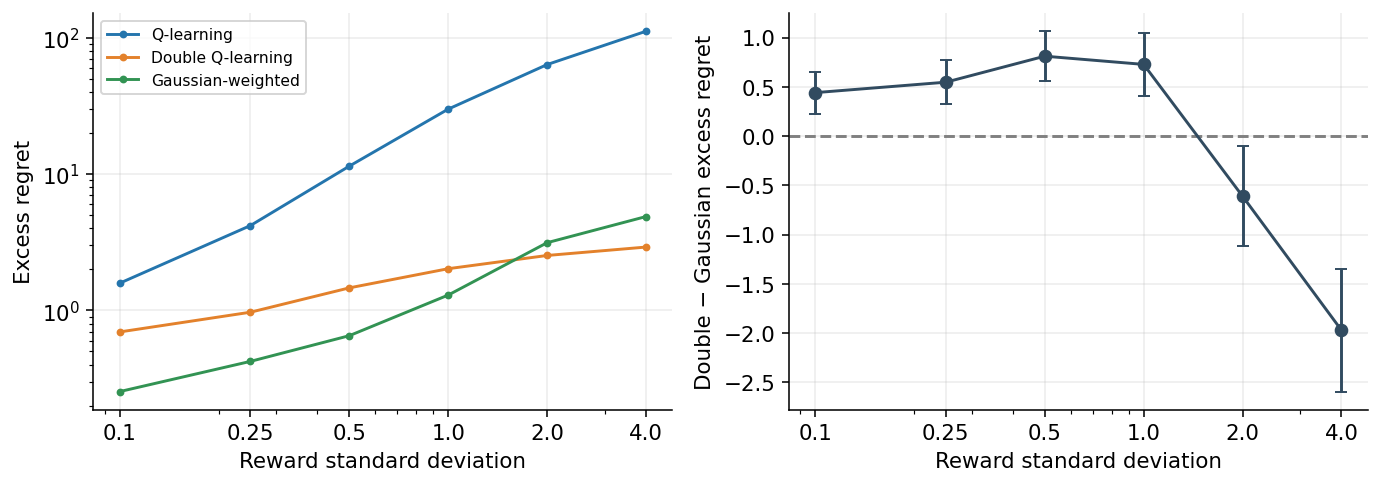

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for method in methods:
    axes[0].plot(noise.sigma, noise[method], '.-', label=labels[method], color=colors[method])
axes[0].set(xscale='log', yscale='log', xlabel='Reward standard deviation', ylabel='Excess regret')
axes[0].legend(fontsize=8)
axes[1].errorbar(noise.sigma, noise.difference,
    yerr=[noise.difference-noise.lower, noise.upper-noise.difference], fmt='o-', capsize=3, color='#314b60')
axes[1].axhline(0, color='gray', ls='--')
axes[1].set(xscale='log', xlabel='Reward standard deviation', ylabel='Double − Gaussian excess regret')
for ax in axes:
    ax.set_xticks(noise.sigma, [str(x) for x in noise.sigma])
fig.tight_layout(); plt.show()

| $\sigma$ | Maximum | Double Q | Gaussian |
|---:|---:|---:|---:|
| 0.1 | 1.5845 | 0.6950 | **0.2535** |
| 0.25 | 4.1995 | 0.9703 | **0.4225** |
| 0.5 | 11.4758 | 1.4645 | **0.6525** |
| 1 | 30.1010 | 2.0255 | **1.2970** |
| 2 | 63.9342 | **2.5333** | 3.1443 |
| 4 | 112.3330 | **2.9203** | 4.8930 |

*Cumulative excess regret on independent validation runs. The intervals in the plot are 95% pointwise intervals for the between-algorithm difference, not adjusted for multiple comparisons.*

The ranking reverses between $\sigma=1$ and $\sigma=2$. At $\sigma=4$, Double Q-learning actually performs better with large learning-rate caps, selecting $c=1$ rather than the small caps one might expect to help in a noisy environment. Gaussian weighting selects $c=0.1$.

Does this mean Double Q-learning is a more accurate estimator when the rewards are very noisy? So far, we have only been measuring how many times the agent goes left.

## Accuracy of the Maximum Estimator

The true value of $B$ is $\mu$, so we can directly evaluate the accuracy of the bootstrap estimate $\widehat V(B)$. Let $e=\widehat V(B)-\mu$. We measure

$$\mathrm{Bias}=\mathbb E[e],\qquad \mathrm{MSE}=\mathbb E[e^2]=\mathrm{Var}(e)+\mathrm{Bias}^2.$$

In experiment 7, we recorded these quantities before each episode under the original adaptive behavior policies. The original diagnostics for $\sigma=0.5$ are shown below.

![Original bias, variance, and MSE curves for sigma 0.5](attachment:Figure_9(1).png)

*Experiment 7: diagnostics across 200 runs with the original learning-rate caps.*
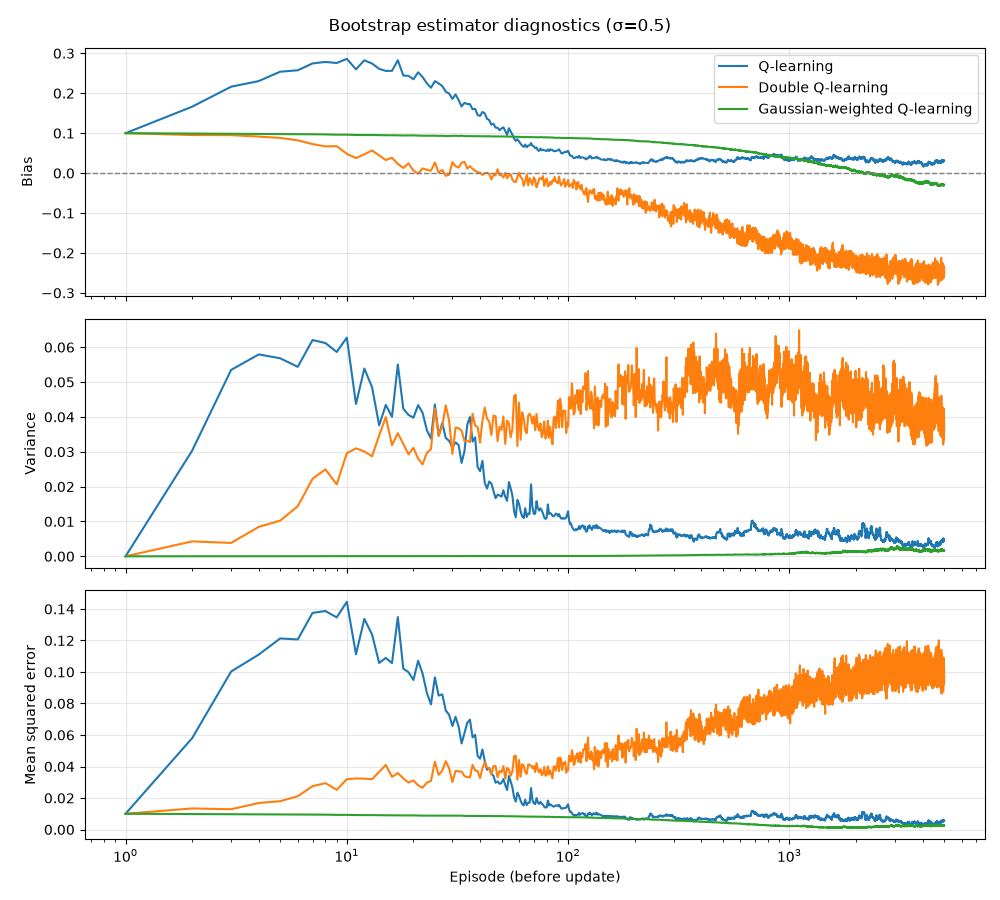

The Double estimator gradually becomes negatively biased; its MSE increases even as the policy learns to avoid the suboptimal branch. There are two reasons this might happen. The algorithms visit $B$ at different rates, and they choose different actions once they get there. We need to control the data collection process.

### A Controlled Sampling Experiment

In experiment 8, we remove state $A$ entirely and sample the ten actions at $B$ uniformly at random. Every estimator receives the same 5,000 observations in each of 1,000 runs (seed 44). We use sample averages ($\alpha_n=1/n$) rather than capped decaying updates. The Double estimator receives a random half of the samples in each table, and we measure a randomly selected cross-estimation direction. The Gaussian estimator uses all the observations.

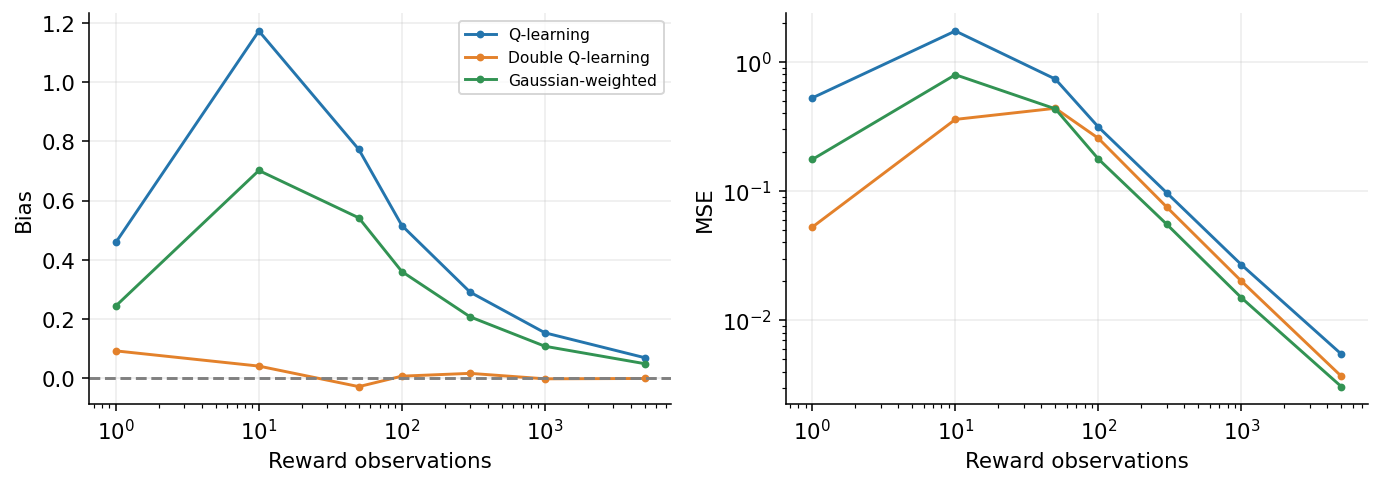

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for method in methods:
    d = bandit[(bandit.sigma == 1) & (bandit.algorithm == method)]
    axes[0].plot(d.samples, d.bias, '.-', label=labels[method], color=colors[method])
    axes[1].plot(d.samples, d.mse, '.-', color=colors[method])
axes[0].axhline(0, color='gray', ls='--')
axes[0].set(xscale='log', xlabel='Reward observations', ylabel='Bias')
axes[1].set(xscale='log', yscale='log', xlabel='Reward observations', ylabel='MSE')
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

After 5,000 observations at $\sigma=1$:

| Estimator | Bias | Variance | MSE |
|---|---:|---:|---:|
| Maximum | 0.06911 | 0.00068 | 0.00546 |
| Double | -0.00099 | 0.00368 | 0.00368 |
| Gaussian | 0.04890 | 0.00067 | **0.00306** |

The Double estimate is now approximately unbiased. However, its variance is substantially larger because each table uses only part of the data. Gaussian weighting trades a little bias for a reduction in variance. At $\sigma=4$, the MSE of Maximum, Double and Gaussian estimation is 0.08729, 0.05894 and 0.04902, respectively.

We have a discrepancy: Double estimation becomes pessimistic in the original RL experiment but not when we sample the same actions uniformly at random. What is it about the RL environment that causes this?

## The Effect of Adaptive Sampling

We return to the full MDP in experiment 8b and vary the exploration policy at $A$ and $B$ independently. This allows us to separate the effect of adaptive state visitation from that of adaptive action selection.

| Configuration | Policy at A | Policy at B |
|---|---|---|
| Original | $\epsilon$-greedy | $\epsilon$-greedy |
| Uniform B | $\epsilon$-greedy | Uniform |
| Uniform A | Uniform | $\epsilon$-greedy |
| Uniform both | Uniform | Uniform |

In each configuration we train for 5,000 episodes across 1,000 runs (seed 55). At $B$, we use sample averages; at $A$, we use $n^{-0.8}$. Random streams for rewards and actions at $B$ are indexed by the number of visits to that state. This means that, for a given estimator and behavior policy at $B$, changing the policy at $A$ does not change the sequence of observations at $B$ at matched visit counts (provided the runs reach the checkpoint).

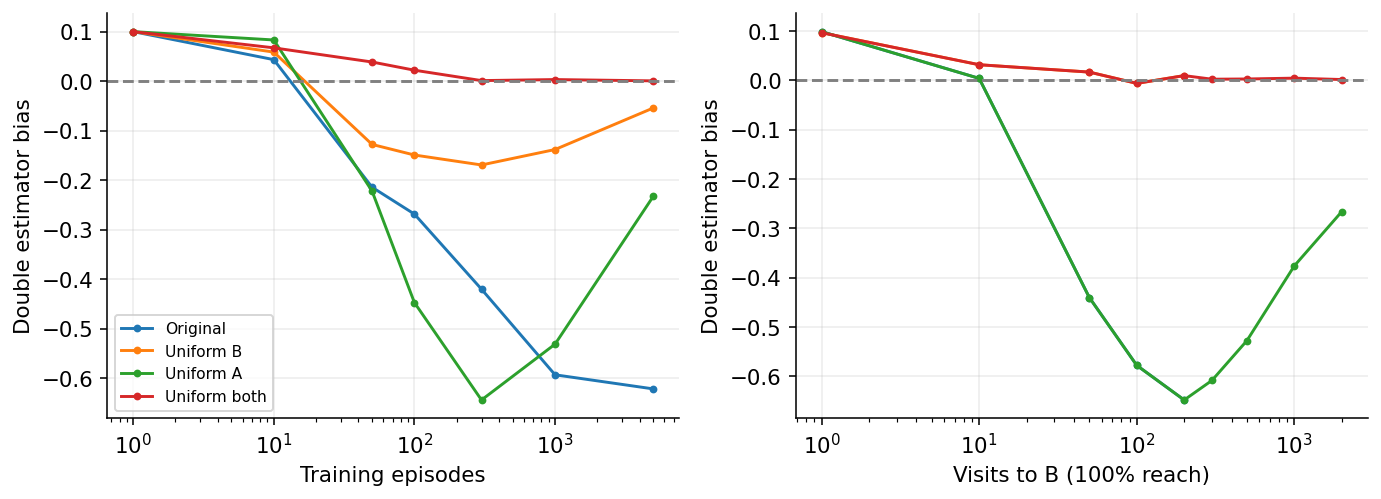

In [6]:
policies = ['Original', 'Uniform B', 'Uniform A', 'Uniform both']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
d = controlled[(controlled.reward_mean == -.1) & (controlled.sigma == 1) & (controlled.method == 'Double Q')]
for policy in policies:
    x = d[(d.policy == policy) & (d.axis == 'episode')]
    axes[0].plot(x.checkpoint, x.bias, '.-', label=policy)
    x = d[(d.policy == policy) & (d.axis == 'visit') & (d.reach == 1)]
    axes[1].plot(x.checkpoint, x.bias, '.-', label=policy)
for ax, xlabel in zip(axes, ['Training episodes', 'Visits to B (100% reach)']):
    ax.axhline(0, color='gray', ls='--'); ax.set(xscale='log', xlabel=xlabel, ylabel='Double estimator bias')
axes[0].legend(fontsize=8); fig.tight_layout(); plt.show()

For $\sigma=1$, the bias after exactly 200 visits to $B$ is -0.64799 when the behavior policy at $B$ is $\epsilon$-greedy, and +0.00944 when it is uniform. This holds regardless of the behavior policy at $A$, because all runs reach this checkpoint and the matched visit-indexed streams are identical. After 5,000 episodes, however, the biases are -0.62207 (original), -0.05428 (uniform B), -0.23272 (uniform A) and +0.00048 (uniform both).

This suggests that adaptive action selection at $B$ creates the large negative bias. Adaptive visitation at $A$ makes it harder to correct. We cannot infer an unbiased estimate at an arbitrary episode by assuming that sample means remain unbiased under a reward-dependent sample size.

### Why Does Double Estimation Become Negatively Biased?

When actions are sampled according to their estimated values, an action that gets a few unlucky rewards will receive fewer subsequent observations. A lucky action gets more opportunities for its estimate to move back towards its true value. The individual estimates need not remain unbiased at a fixed training horizon.

There is another complication in Double Q-learning. Although rewards are assigned to the two tables independently at random, both tables influence the behavior policy. Consider the following illustrative example where every action has an expected reward of 0.1.

| Action | $Q_1$ | $Q_2$ | $(Q_1+Q_2)/2$ |
|---|---:|---:|---:|
| 1 | 0.8 | -0.9 | -0.05 |
| 2 | -0.7 | 0.6 | -0.05 |
| 3 | 0.1 | 0.1 | 0.10 |

The behavior policy mostly selects action 3, but the cross-estimates are $Q_2(B,1)=-0.9$ and $Q_1(B,2)=-0.7$. The action that looks best in one table can look terrible in the other. Under adaptive sampling, splitting the data alone does not guarantee independent selection and evaluation errors. This example illustrates a possible mechanism; the experiments do not separately measure all of its covariance terms.

Gaussian weighting has a related problem. Underexplored actions can have negative sample means and large standard errors, so they can still receive appreciable weights. Ordinary Maximum estimation can ignore these actions as long as a single action is sufficiently well estimated.

## What if Going Left is Optimal?

The original environment is rather forgiving of underestimation. The true value of $B$ is negative. An estimator of -2.0 is much worse than an estimator of -0.09, but both favor the correct action at $A$.

In experiment 8c we change only the mean from -0.1 to +0.1, retaining the learning rates, seeds, reward standard deviations and four behavior-policy configurations of experiment 8b. Now, the optimal policy goes left. Since every action at $B$ is equally good, we can evaluate the greedy policy exactly without collecting any extra reward samples.

Let $p_L$ be the probability of going left under the frozen greedy policy, with ties broken uniformly. The expected return is $\mu p_L$ and the policy loss is $\max(0,\mu)-\mu p_L$. We use greedy-policy accuracy rather than training regret as the primary metric from here on. Both are useful, but they measure different things.

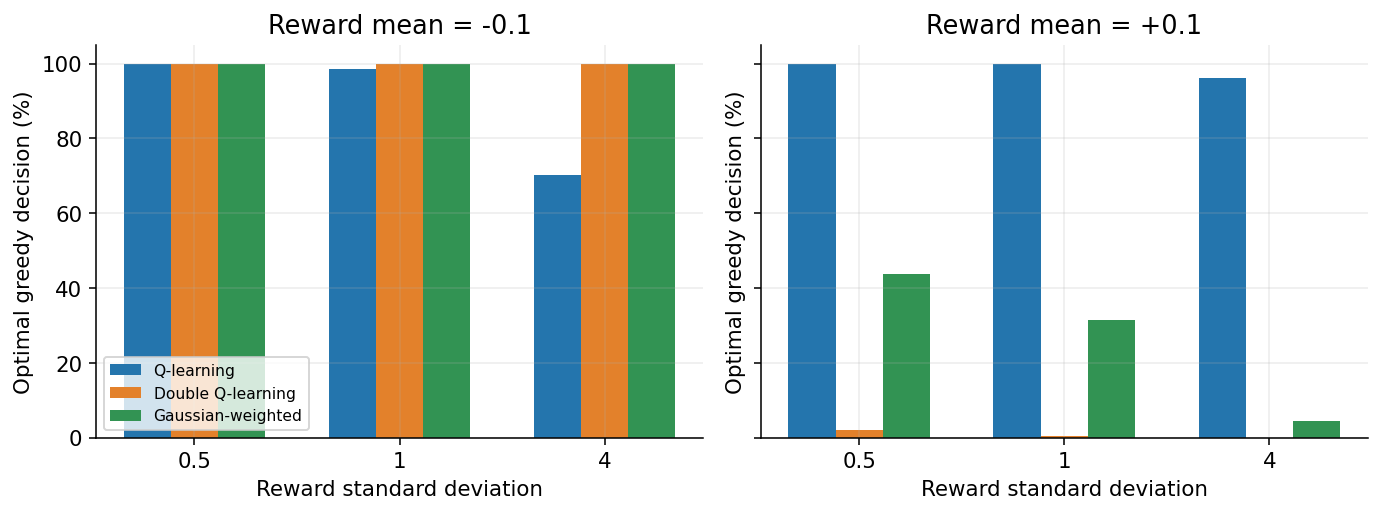

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, mu in zip(axes, [-.1,.1]):
    d = controlled[(controlled.reward_mean == mu) & (controlled.policy == 'Original') & (controlled.axis == 'episode') & (controlled.checkpoint == 5000)]
    x = np.arange(3)
    for i, method in enumerate(methods):
        y = d[d.method == method].sort_values('sigma').greedy_optimal * 100
        ax.bar(x+(i-1)*.23, y, .23, color=colors[method], label=labels[method])
    ax.set(title=f'Reward mean = {mu:+g}', ylabel='Optimal greedy decision (%)', ylim=(0,105), xlabel='Reward standard deviation', xticks=x, xticklabels=['0.5','1','4'])
axes[0].legend(fontsize=8, loc='lower left'); fig.tight_layout(); plt.show()

For $\mu=+0.1$, with ordinary $\epsilon$-greedy exploration:

| $\sigma$ | Q-learning | Double Q-learning | Gaussian |
|---:|---:|---:|---:|
| 0.5 | 100% | 2.1% | 43.8% |
| 1 | 99.9% | 0.3% | 31.5% |
| 4 | 96.2% | 0.0% | 4.5% |

At $\sigma=1$, Double Q-learning's average estimate of $V(B)$ is -0.4760, and the agent visits $B$ only 335 times on average. Ordinary Q-learning visits it 4,735 times. The Double agent rarely gets enough observations to correct its pessimistic estimate.

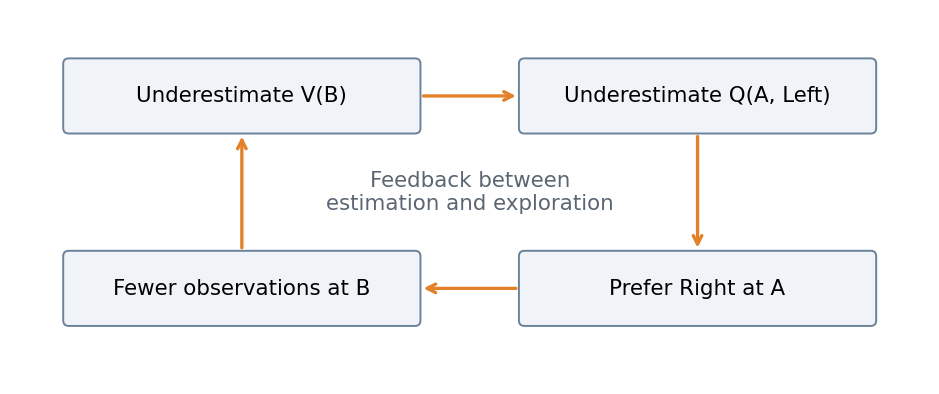

In [8]:
fig, ax = plt.subplots(figsize=(8.4, 3.4)); ax.axis('off'); ax.set(xlim=(0,10),ylim=(0,4))
items = [(2.5,3.1,'Underestimate V(B)'),(7.5,3.1,'Underestimate Q(A, Left)'),(7.5,1.0,'Prefer Right at A'),(2.5,1.0,'Fewer observations at B')]
for x,y,s in items:
    ax.add_patch(FancyBboxPatch((x-1.9,y-.35),3.8,.7,boxstyle='round,pad=.06',fc='#f0f4f8',ec='#6a839a'))
    ax.text(x,y,s,ha='center',va='center',fontsize=11)
for a,b in [((4.45,3.1),(5.55,3.1)),((7.5,2.7),(7.5,1.4)),((5.55,1),(4.45,1)),((2.5,1.4),(2.5,2.7))]:
    ax.annotate('',b,a,arrowprops=dict(arrowstyle='->',lw=1.7,color='#e3812b'))
ax.text(5,2.05,'Feedback between\nestimation and exploration',ha='center',va='center',color='#5b6673')
plt.show()

If the agent consistently prefers Right, $\epsilon=0.1$ gives it a probability of 0.05 of visiting $B$. A persistently non-greedy action at $B$ has probability 0.01 of being selected during a visit. Over 5,000 episodes this amounts to only 2.5 expected observations for that action, split again between two tables for Double Q-learning. This is a finite-sample problem; it does not contradict asymptotic convergence under sufficient exploration.

Forcing uniform exploration at $A$ alone helps little: at $\sigma=1$, Double Q-learning achieves 5.9% final greedy accuracy. Uniform exploration at $B$ improves this to 57.2%, and uniform exploration at both states to 96.3%. The distribution of observations among actions is as important as the total number of visits.

## Propagating Uncertainty

There is no reason that the estimates we use for learning the value function must also be the only quantities used to guide exploration. Suppose we maintain a separate estimate $u(s,a)$ of the epistemic uncertainty in $Q(s,a)$.

In [The Uncertainty Bellman Equation and Exploration](https://proceedings.mlr.press/v80/odonoghue18a.html) (O'Donoghue et al., 2018), the authors derive a recursive upper bound on the posterior variance of policy action values under assumptions about the MDP. In our much simpler setting the transition from $A$ to $B$ is deterministic, its immediate reward is known, and the next reward mean is the only uncertain parameter. For a fixed deterministic policy that selects $a'$ at $B$,

$$Q^\pi(A,L)=\gamma Q^\pi(B,a'),\qquad u^\pi(A,L)=\gamma^2u^\pi(B,a').$$

If the reward variance $\sigma^2$ is known and we use a Gaussian prior on the mean with variance $\sigma^2$, the posterior variance of the mean at $B$ is

$$u(B,a)=\frac{\sigma^2}{N(B,a)+1}.$$

The reward variance itself does not shrink; our uncertainty about the expected reward does. For a changing stochastic behavior policy we use a SARSA-style uncertainty update, following the practical UBE idea:

$$u(A,L)\leftarrow u(A,L)+\eta[u(B,a')-u(A,L)],$$

where $a'$ is the action actually selected at $B$, before its reward is observed, $\gamma=1$ and $\eta=0.1$. We initialize $u(A,L)=\sigma^2$ and set $u(A,R)=0$. We can now explore by drawing approximate Thompson samples from each action's estimated value distribution.

In [9]:
@jax.jit
def thompson(key, q, u, beta):
    return jnp.argmax(q + beta * jnp.sqrt(u) * jax.random.normal(key, q.shape))

def update_uncertainty(u_left, u_next, eta=.1):
    return u_left + eta * (u_next - u_left)

These are the essential operations; the experiment uses random tie-breaking and separate random streams. The centers of the sampling distributions are TD estimates, not exact posterior means, and Double uses pooled counts for the uncertainty bonus. We are testing an exploration heuristic motivated by UBE, not claiming its theoretical bound for a changing policy or biased value estimates.

### Local vs. Propagated Uncertainty

In experiment 8d we compare six behavior-policy configurations. Local Thompson sampling is an important control: it uses the same exploration bonus at $B$, but uses the local count $N(A,L)$ instead of propagating uncertainty from the next action.

| Behavior policy | Parameters |
|---|---|
| $\epsilon$-greedy | $\epsilon=0.1$ |
| Local UCB | $c_A=0.1$, $c_B=0.5$ |
| Local Thompson sampling | $\beta=1,2$; $u(A,L)=\sigma^2/(N(A,L)+1)$ |
| UBE Thompson sampling | $\beta=1,2$; propagated $u(A,L)$ |

In each case, the three value-learning updates remain unchanged. We run 1,000 agents for 5,000 episodes (seed 56), with $\mu\in\{-1,+1\}$ and $\sigma\in\{0.5,1,4\}$, giving 108 configurations. Note that we increased the magnitude of the mean from 0.1 to 1 in this experiment. This is a different decision problem, so we include fresh baselines rather than compare its absolute numbers directly to experiment 8c.

The most interesting result occurs at $\mu=+1,\sigma=4$, where Double Q-learning with $\epsilon$-greedy exploration initially learns a better policy, then becomes progressively worse.

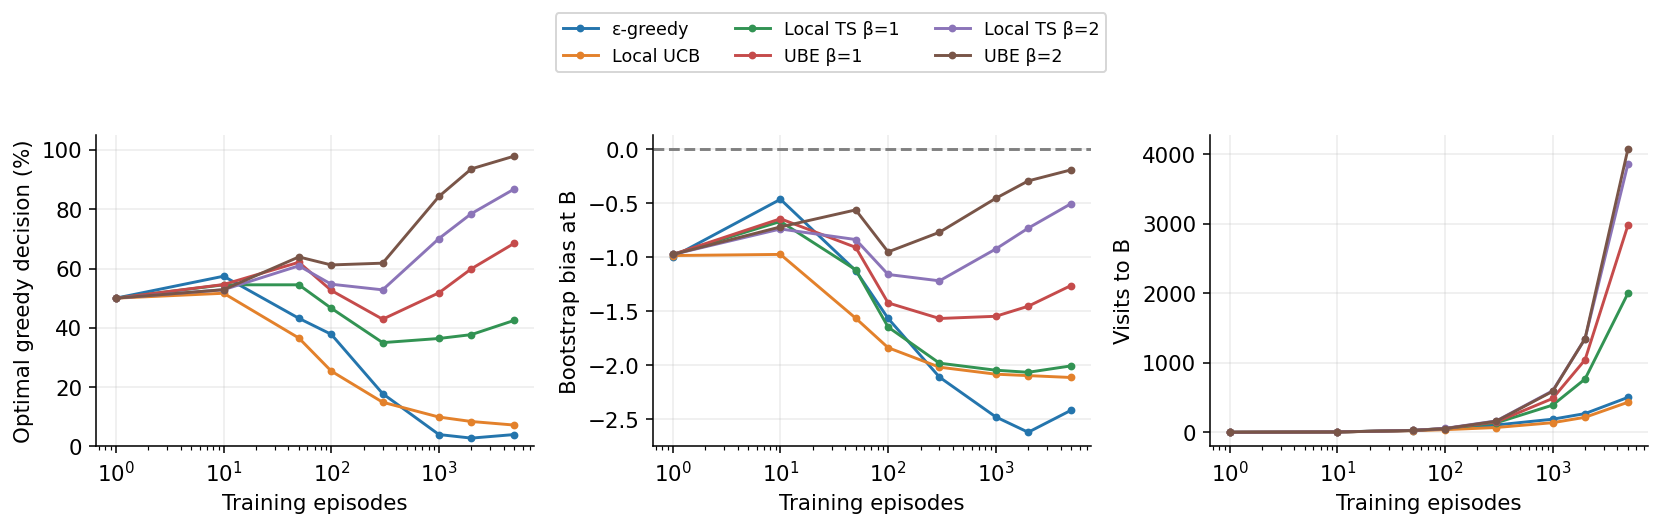

In [10]:
policy_keys = [('epsilon',0),('ucb',0),('local_ts',1),('ube',1),('local_ts',2),('ube',2)]
policy_labels = ['ε-greedy','Local UCB','Local TS β=1','UBE β=1','Local TS β=2','UBE β=2']
policy_colors = ['#2475ad','#e3812b','#329353','#c54b4b','#8b74b8','#795548']
d = ube[(ube.mu == 1) & (ube.sigma == 4) & (ube.algorithm == 'Double Q') & (ube.episode > 0)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.65))
for (policy,beta),label,c in zip(policy_keys,policy_labels,policy_colors):
    x = d[(d.policy == policy) & (d.beta == beta)].sort_values('episode')
    for ax,metric,scale in zip(axes,['greedy_optimal','b_bias','b_visits'],[100,1,1]):
        ax.plot(x.episode,x[metric]*scale,'.-',color=c,label=label)
for ax,y in zip(axes,['Optimal greedy decision (%)','Bootstrap bias at B','Visits to B']):
    ax.set(xscale='log', xlabel='Training episodes', ylabel=y)
axes[0].set_ylim(0,105);axes[1].axhline(0,ls='--',color='gray')
fig.legend(*axes[0].get_legend_handles_labels(),loc='upper center',ncol=3,fontsize=9,bbox_to_anchor=(.5,1.04))
fig.tight_layout(rect=[0,0,1,.83]); plt.show()

| Exploration | Q-learning | Double Q | Gaussian |
|---|---:|---:|---:|
| $\epsilon$-greedy | 100% | 4.0% | 97.7% |
| Local UCB | 99.9% | 7.2% | 71.1% |
| Local TS ($\beta=1$) | 100% | 42.5% | 100% |
| UBE ($\beta=1$) | 100% | 68.5% | 100% |
| Local TS ($\beta=2$) | 100% | 86.8% | 100% |
| UBE ($\beta=2$) | 100% | 97.9% | 100% |

*Final greedy-policy accuracy at $\mu=1,\sigma=4$.*

Increasing the Thompson sampling scale helps substantially, even without propagation. At the same scale, UBE further improves Double Q-learning by 26.0 percentage points for $\beta=1$ (paired 95% CI [23.25, 28.75]) and 11.1 points for $\beta=2$ ([9.15, 13.05]). These are pointwise normal intervals on the paired differences in exact greedy returns; here the optimality gap is 1, so return differences equal accuracy differences.

For Double Q-learning, UBE with $\beta=2$ increases the average number of visits to $B$ from about 502 to 4,069 and reduces the magnitude of the average bootstrap bias from 2.418 to 0.191. The average minimum action count at $B$ increases from 3.0 to 194.8. Propagating uncertainty helps counteract the feedback loop, although it has not produced a better final policy than ordinary Q-learning.

### The Cost of Exploration

At $\mu=-1$, all three estimators achieve approximately 100% final accuracy under all six exploration settings. Nevertheless, at $\sigma=4$, UBE with $\beta=2$ takes the suboptimal left action approximately 1,542 times for ordinary Q-learning, 695 for Double, and 1,262 for Gaussian weighting. Under $\epsilon$-greedy exploration, the corresponding counts are approximately 347, 265 and 289.

The additional exploration does not improve the final policy in this easy negative-mean case. It has a real cost if rewards during learning matter. This is why we distinguish cumulative regret from final policy quality rather than discard either metric.

## How Accurately Did We Learn the Values?

Final policy accuracy saturates at 100% in many of these configurations. However, the learned values can still differ substantially. We know the exact value of the left action at $A$, so we measure its MSE across runs independently of the behavior policy. For Double Q-learning we use the average of its two tables.

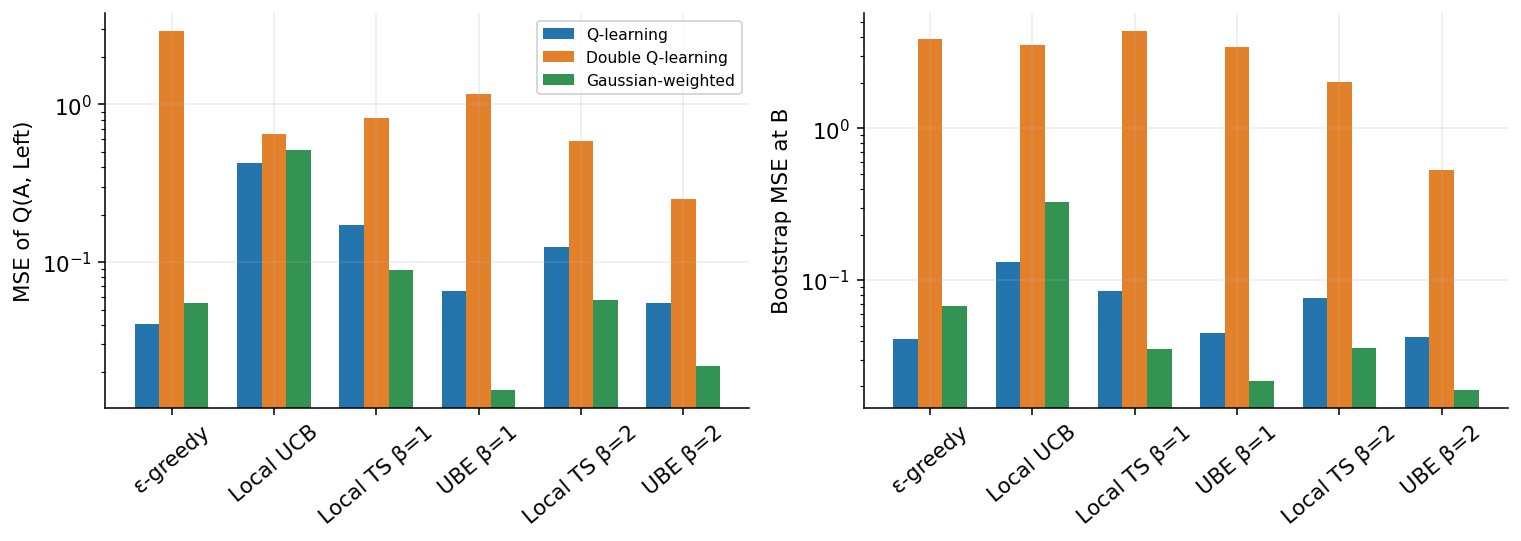

In [11]:
final = ube[ube.episode == 5000].copy()
final['exploration'] = [dict(zip(policy_keys,policy_labels))[(p,b)] for p,b in zip(final.policy,final.beta)]
assert len(final) == 108
agg = final.groupby(['exploration','algorithm'])[['a_mse','b_mse','greedy_optimal']].mean()
a = agg.a_mse.unstack().reindex(index=policy_labels, columns=methods)
b = agg.b_mse.unstack().reindex(index=policy_labels, columns=methods)
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax,table,label in zip(axes,[a,b],['MSE of Q(A, Left)','Bootstrap MSE at B']):
    x=np.arange(len(policy_labels))
    for i,method in enumerate(methods):
        ax.bar(x+(i-1)*.24,table[method],.24,color=colors[method],label=labels[method])
    ax.set(yscale='log',ylabel=label,xticks=x,xticklabels=policy_labels)
    ax.tick_params(axis='x', labelrotation=40)
axes[0].legend(fontsize=8);fig.tight_layout();plt.show()

Averaging the final $Q(A,L)$ MSE equally across the six environments gives:

| Exploration | Q-learning | Double Q | Gaussian |
|---|---:|---:|---:|
| $\epsilon$-greedy | 0.040685 | 2.920891 | 0.055359 |
| Local UCB | 0.425724 | 0.651531 | 0.516532 |
| Local TS ($\beta=1$) | 0.171735 | 0.826783 | 0.089484 |
| UBE ($\beta=1$) | 0.065696 | 1.171102 | **0.015481** |
| Local TS ($\beta=2$) | 0.123874 | 0.589592 | 0.057670 |
| UBE ($\beta=2$) | 0.054938 | 0.252417 | 0.021841 |

Gaussian weighting with UBE ($\beta=1$) has the lowest aggregate upstream MSE and achieves 100% final greedy accuracy across the six tested environments. Its mean MSE is about 62% lower than that of the best fixed Q-learning configuration by this metric ($\epsilon$-greedy). The lowest aggregate bootstrap MSE at $B$ is 0.018993 (Gaussian + UBE, $\beta=2$), compared to 0.041140 (Maximum + $\epsilon$-greedy) and 0.532741 (Double + UBE, $\beta=2$).

These aggregate comparisons are descriptive. Selecting the best configuration on the same runs is not independent validation, and averaging raw MSE gives high-noise environments more influence. Also, these are errors in the bootstrap estimator at $B$ and the upstream action value at $A$. They are not MSEs over the entire Q-function; the individual ten action estimates at $B$ were not retained in the CSV.

## Conclusion

We started with a statistical question: how do we estimate the maximum of a set of noisy estimates? The controlled sampling experiment suggests a useful bias–variance tradeoff for Gaussian weighting. But the behavior of the estimators in an RL algorithm is very different. Under adaptive sampling, Double estimation can become substantially negatively biased. If the resulting estimate of a downstream state is too pessimistic, the agent stops visiting it frequently enough to correct the error.

In the original maximization-bias environment, this pessimism helps the agent avoid a genuinely suboptimal state. Reversing the reward mean reveals that the same mechanism can prevent it from learning the optimal policy. Better exploration, particularly when it accounts for downstream uncertainty, can mitigate the problem without changing the value-learning update.

For this MDP, ordinary Q-learning remains a remarkably strong baseline for policy learning. Gaussian weighting paired with uncertainty-driven exploration is interesting when accurate value estimates matter as well. Whether these advantages survive a more complex MDP remains an open question. The next steps are to test the uncertainty methods at the smaller mean gap ($\mu=\pm0.1$), estimate reward variances from data instead of giving them to the exploration policy, tune and validate exploration parameters independently, and compare against the exact optimal Q-function in stochastic cliff walking and other multistep environments.

### Reproducibility and References

The plots based on experiments 8–8d are generated from the original logged results, not new training runs. Experiment 6b's table and confidence intervals were transcribed from the original user-provided console output. The earlier embedded plots are original saved figures; where the corresponding numeric logs could not be recovered, no precise early result is quoted. The notebook contains the data needed to regenerate its charts and the accompanying source bundle includes the available experiment scripts, original logs and CSVs. The displayed JAX functions are minimal illustrative versions; the scripts contain the full experiment implementations.

- Sutton and Barto, [Reinforcement Learning: An Introduction, 2nd edition](http://incompleteideas.net/book/the-book-2nd.html), 2018, Section 6.7 and Example 6.7.
- van Hasselt, [Double Q-learning](https://proceedings.neurips.cc/paper_files/paper/2010/hash/091d584fced301b442654dd8c23b3fc9-Abstract.html), 2010.
- D'Eramo, Restelli and Nuara, [Estimating Maximum Expected Value through Gaussian Approximation](https://proceedings.mlr.press/v48/deramo16.html), 2016.
- D'Eramo et al., [Gaussian Approximation for Bias Reduction in Q-Learning](https://jmlr.org/papers/v22/20-633.html), 2021.
- O'Donoghue et al., [The Uncertainty Bellman Equation and Exploration](https://proceedings.mlr.press/v80/odonoghue18a.html), 2018.